# BraTS EDA and Medigan Generative Deepfake Dataset

This notebook explores BraTS, then builds a balanced **real / fake** dataset.

Fake tumors are **not** stamped with OpenCV (`cv2.seamlessClone`).
They are synthesized by the official pretrained medigan inpainting model
`00007_INPAINT_BRAIN_MRI` (Kim et al., Medical Physics).

For every selected BraTS slice we send the four MRI modalities
(FLAIR, T1, T1c, T2) into the model. It inpaints a realistic tumor
into the brain tissue and also returns the generated anomaly mask.

```
dataset/
    train/real/   train/fake/   train/real_masks/   train/fake_masks/
    val/real/     val/fake/     val/real_masks/     val/fake_masks/
    test/real/    test/fake/    test/real_masks/    test/fake_masks/
```

Patients are split **70% / 15% / 15% before** generation, so no patient
appears in more than one split. Real masks are empty. Fake masks come
from the medigan model (not from BraTS labels).


## 0. Install and imports

If the packages are already installed this cell is just a bit slow, that is fine.


In [1]:
%pip install -q numpy matplotlib pandas h5py nibabel pillow torch torchvision medigan tqdm



Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os
import gc
import glob
import random
import shutil
import tempfile
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import h5py
import nibabel as nib
import torch
from PIL import Image
from tqdm import tqdm

%matplotlib inline

random.seed(42)
np.random.seed(42)
warnings.filterwarnings("ignore", message="Your specified number of images")



## 1. Paths and settings

The BraTS copy in this project is already split into 2D `.h5` slices (Kaggle format).
Each file holds 4 MRI sequences: FLAIR, T1, T1ce, T2.

`USE_ALL_PATIENTS = True` uses every volume. We keep the middle slices
(near each volume's median slice) so empty top/bottom cuts are skipped.

This notebook is meant to run on **GPU**. The first generation call
downloads the medigan weights if they are not cached yet.


In [3]:
# run from the ai folder if the notebook was opened from the project root
if Path("ai/data").exists():
    os.chdir("ai")

data_dir = Path("data/BraTS2020_training_data/content/data")
meta_csv = Path("data/BraTS20 Training Metadata.csv")
out_dir = Path("dataset")
medigan_work_dir = Path("work_deepfake/medigan_batches")
MEDIGAN_MODEL_ID = "00007_INPAINT_BRAIN_MRI"

USE_ALL_PATIENTS = True
N_SAMPLES = 100          # only used when USE_ALL_PATIENTS = False
MIDDLE_RADIUS = 31       # keep slices near the middle of each volume
TARGET_SLICES = 22876    # exact number of real slices sent to medigan
IMG_SIZE = 256
MEDIGAN_BATCH_SIZE = 32  # disk staging size; the GAN still runs one slice at a time
MODALITY_NAMES = ["FLAIR", "T1", "T1c", "T2"]

print("data_dir exists:", data_dir.exists())
print("meta_csv exists:", meta_csv.exists())
print("=== GPU CHECK ===")
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA is unavailable in this notebook kernel. Select a CUDA-enabled "
        "Python environment and restart the kernel before generating."
    )
print("GPU:", torch.cuda.get_device_name(0))
print("CUDA version:", torch.version.cuda)
print("GPU memory:", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2), "GB")



data_dir exists: True
meta_csv exists: True
=== GPU CHECK ===
PyTorch version: 2.6.0+cu124
CUDA available: True
GPU: Quadro P4000
CUDA version: 12.4
GPU memory: 8.0 GB


## 2. Exploratory Data Analysis

First we look at what is in the folder, then we load a few slices, print their shapes, plot them, and draw intensity histograms.


In [4]:
h5_files = sorted(glob.glob(str(data_dir / "*.h5")))
png_files = sorted(glob.glob(str(data_dir / "*.png")) + glob.glob(str(data_dir / "*.jpg")))
nii_files = sorted(glob.glob(str(data_dir / "*.nii")) + glob.glob(str(data_dir / "*.nii.gz")))

print("HDF5 slices (.h5):", len(h5_files))
print("Standard images (.png / .jpg):", len(png_files))
print("NIfTI files (.nii / .nii.gz):", len(nii_files))
print("example h5 file:", Path(h5_files[0]).name if h5_files else None)



HDF5 slices (.h5): 57195
Standard images (.png / .jpg): 0
NIfTI files (.nii / .nii.gz): 0
example h5 file: volume_100_slice_0.h5


In [5]:
meta = pd.read_csv(meta_csv)
print(meta.head())
print()
print("rows:", len(meta))
print("volumes:", meta["volume"].nunique())
print("slices with tumor (target=1):", int((meta["target"] == 1).sum()))
print("slices without tumor (target=0):", int((meta["target"] == 0).sum()))



                                          slice_path  target  volume  slice  \
0  ../input/brats2020-training-data/BraTS2020_tra...       0      41      0   
1  ../input/brats2020-training-data/BraTS2020_tra...       0      41      1   
2  ../input/brats2020-training-data/BraTS2020_tra...       0      41      2   
3  ../input/brats2020-training-data/BraTS2020_tra...       0      41      3   
4  ../input/brats2020-training-data/BraTS2020_tra...       0      41      4   

   label0_pxl_cnt  label1_pxl_cnt  label2_pxl_cnt  background_ratio  
0               0               0               0               1.0  
1               0               0               0               1.0  
2               0               0               0               1.0  
3               0               0               0               1.0  
4               0               0               0               1.0  

rows: 57195
volumes: 369
slices with tumor (target=1): 24422
slices without tumor (target=0): 32773


### Helper: load any scan (HDF5, NIfTI, or a normal image)

- `.h5` → already a 2D slice with 4 channels
- `.nii` / `.nii.gz` → 3D (or 4D) volume, we take the **middle slice**
- `.png` / `.jpg` → loaded as a normal 2D image


In [6]:
def to_uint8(img):
    # scale to 0-255 so we can plot and save as png
    img = img.astype(np.float32)
    vmin, vmax = img.min(), img.max()
    if vmax - vmin < 1e-8:
        return np.zeros(img.shape, dtype=np.uint8)
    img = (img - vmin) / (vmax - vmin)
    return (img * 255).astype(np.uint8)


def get_middle_slice(vol):
    # for a 3D or 4D NIfTI volume, keep only the middle 2D slice
    if vol.ndim == 2:
        return vol
    if vol.ndim == 3:
        # (H, W, C) with C = 3 or 4 is already a 2D multi-channel slice
        if vol.shape[-1] <= 4:
            return vol
        z = vol.shape[2] // 2
        return vol[:, :, z]
    if vol.ndim == 4:
        z = vol.shape[2] // 2
        return vol[:, :, z, :]
    return vol


def load_image(path):
    path = str(path)
    name = path.lower()

    if name.endswith(".h5"):
        with h5py.File(path, "r") as f:
            img = f["image"][()]
            mask = f["mask"][()] if "mask" in f else None
        return img, mask

    if name.endswith(".nii") or name.endswith(".nii.gz"):
        vol = nib.load(path).get_fdata()
        img = get_middle_slice(vol)
        return img, None

    img = np.array(Image.open(path))
    return img, None


def as_modalities(img):
    # always give 4 channels (FLAIR, T1, T1ce, T2)
    if img.ndim == 2:
        return [img, img, img, img]
    channels = [img[:, :, i] for i in range(img.shape[-1])]
    while len(channels) < 4:
        channels.append(channels[-1])
    return channels[:4]


def h5_name_from_row(row):
    return Path(str(row["slice_path"]).replace("\\", "/")).name



### 2.1 HDF5 slices

Each `.h5` file stores:

- `image` with shape `(240, 240, 4)` → FLAIR, T1, T1ce, T2
- `mask` with shape `(240, 240, 3)` → tumor sub-regions (if present)

The pixel values are already z-score normalized, so we scale them only for display.


In [7]:
# a few slices from the middle of one volume (more brain tissue than the edges)
sample_names = [
    "volume_41_slice_70.h5",
    "volume_41_slice_80.h5",
    "volume_41_slice_90.h5",
]
sample_paths = [data_dir / n for n in sample_names]

for p in sample_paths:
    img, mask = load_image(p)
    print(p.name)
    print("  image shape:", img.shape, " dtype:", img.dtype,
          " min:", round(float(img.min()), 3), " max:", round(float(img.max()), 3))
    if mask is not None:
        print("  mask  shape:", mask.shape, " dtype:", mask.dtype,
              " tumor pixels:", int(mask.sum()))



volume_41_slice_70.h5
  image shape: (240, 240, 4)  dtype: float64  min: -0.635  max: 7.549
  mask  shape: (240, 240, 3)  dtype: uint8  tumor pixels: 1047
volume_41_slice_80.h5
  image shape: (240, 240, 4)  dtype: float64  min: -0.631  max: 7.251
  mask  shape: (240, 240, 3)  dtype: uint8  tumor pixels: 1096
volume_41_slice_90.h5
  image shape: (240, 240, 4)  dtype: float64  min: -0.611  max: 8.843
  mask  shape: (240, 240, 3)  dtype: uint8  tumor pixels: 832


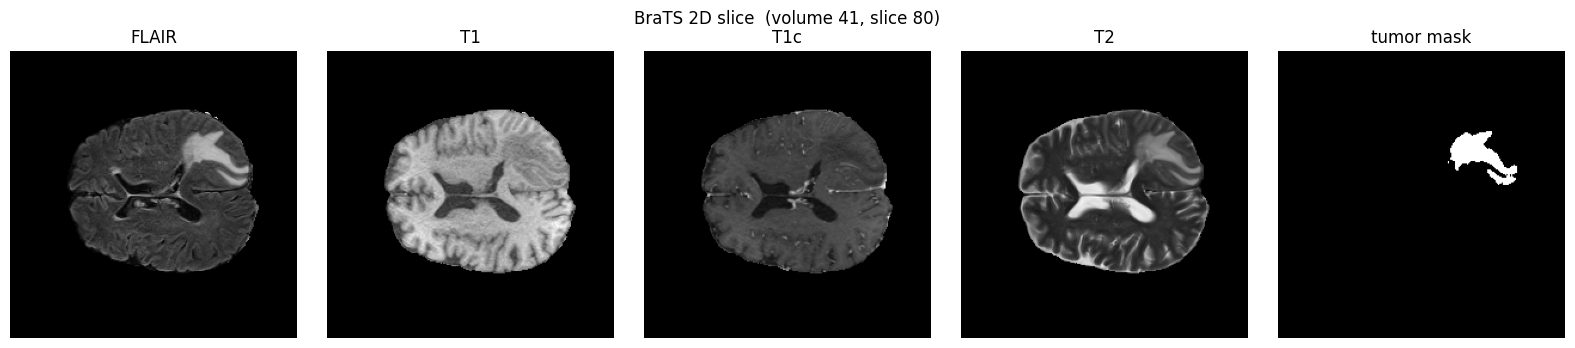

In [8]:
img, mask = load_image(sample_paths[1])   # volume_41, slice 80

fig, axes = plt.subplots(1, 5, figsize=(16, 3.5))
for i, name in enumerate(MODALITY_NAMES):
    axes[i].imshow(to_uint8(img[:, :, i]), cmap="gray")
    axes[i].set_title(name)
    axes[i].axis("off")

if mask is not None:
    axes[4].imshow(mask.max(axis=2), cmap="gray")
    axes[4].set_title("tumor mask")
    axes[4].axis("off")
else:
    axes[4].axis("off")

plt.suptitle("BraTS 2D slice  (volume 41, slice 80)")
plt.tight_layout()
plt.show()



### 2.2 Pixel intensity histograms (HDF5)


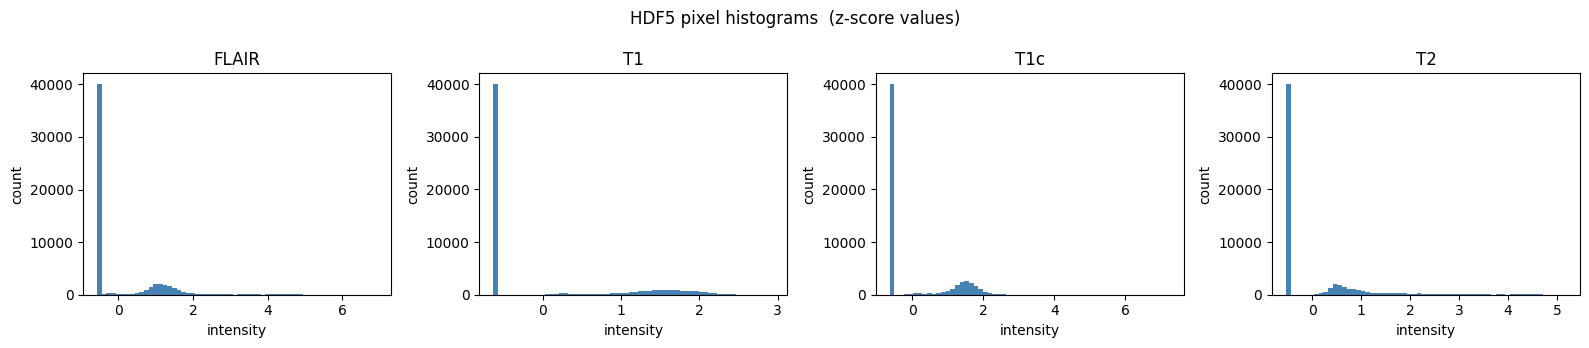

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for i, name in enumerate(MODALITY_NAMES):
    axes[i].hist(img[:, :, i].ravel(), bins=60, color="steelblue")
    axes[i].set_title(name)
    axes[i].set_xlabel("intensity")
    axes[i].set_ylabel("count")

plt.suptitle("HDF5 pixel histograms  (z-score values)")
plt.tight_layout()
plt.show()



### 2.3 Same slice saved as PNG and as NIfTI

The dataset here is `.h5`, but the rest of the pipeline should also work with
normal images and NIfTI volumes. We save one example in both formats, load
them back, and plot histograms so those two loaders are actually tested.


In [10]:
demo_dir = Path("demo_formats")
demo_dir.mkdir(exist_ok=True)

flair_u8 = to_uint8(img[:, :, 0])
png_path = demo_dir / "demo_flair.png"
Image.fromarray(flair_u8).save(png_path)

slices = []
for s in range(70, 91):
    sl, _ = load_image(data_dir / f"volume_41_slice_{s}.h5")
    slices.append(sl[:, :, 0])
vol = np.stack(slices, axis=2)
nii_path = demo_dir / "demo_flair.nii.gz"
nib.save(nib.Nifti1Image(vol.astype(np.float32), np.eye(4)), nii_path)

print("saved png :", png_path, " shape", flair_u8.shape)
print("saved nifti:", nii_path, " shape", vol.shape)



saved png : demo_formats\demo_flair.png  shape (240, 240)
saved nifti: demo_formats\demo_flair.nii.gz  shape (240, 240, 21)


PNG  loaded shape: (240, 240)
NIfTI loaded shape (middle slice): (240, 240)


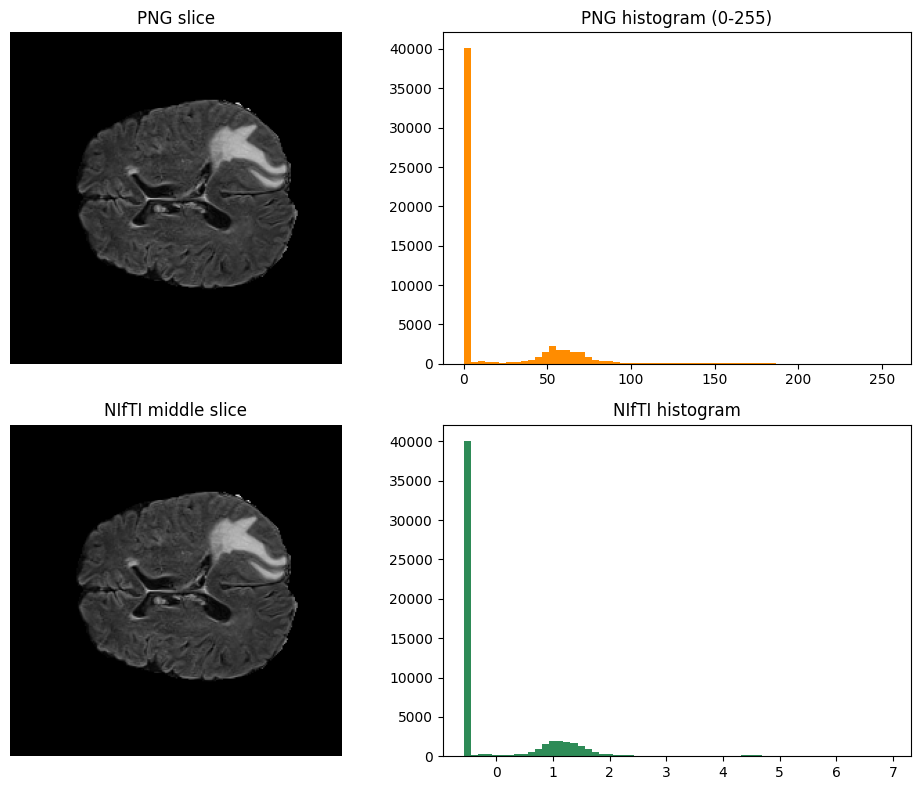

In [11]:
png_img, _ = load_image(png_path)
nii_img, _ = load_image(nii_path)

print("PNG  loaded shape:", png_img.shape)
print("NIfTI loaded shape (middle slice):", nii_img.shape)

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes[0, 0].imshow(png_img, cmap="gray")
axes[0, 0].set_title("PNG slice")
axes[0, 0].axis("off")
axes[0, 1].hist(np.array(png_img).ravel(), bins=60, color="darkorange")
axes[0, 1].set_title("PNG histogram (0-255)")

axes[1, 0].imshow(to_uint8(nii_img), cmap="gray")
axes[1, 0].set_title("NIfTI middle slice")
axes[1, 0].axis("off")
axes[1, 1].hist(np.array(nii_img).ravel(), bins=60, color="seagreen")
axes[1, 1].set_title("NIfTI histogram")

plt.tight_layout()
plt.show()



## 3. Choose slices and split patients

We keep **middle** slices of every patient (around that volume's median slice)
so the top/bottom empty cuts are skipped.

Patients are split **70 / 15 / 15 before** any fake is created.
The same volume never appears in train, validation, and test.


In [12]:
vol_mid = meta.groupby("volume")["slice"].median()
good = meta.copy()
good["mid"] = good["volume"].map(vol_mid)
good = good[(good["slice"] - good["mid"]).abs() <= MIDDLE_RADIUS].copy()
good["distance_from_middle"] = (good["slice"] - good["mid"]).abs()
good = (
    good.sort_values(["distance_from_middle", "volume", "slice"])
    .head(TARGET_SLICES)
    .drop(columns=["distance_from_middle"])
    .reset_index(drop=True)
)
assert len(good) == TARGET_SLICES, f"expected {TARGET_SLICES} slices, got {len(good)}"

patients = good["volume"].unique()
np.random.shuffle(patients)
if not USE_ALL_PATIENTS:
    patients = patients[: min(N_SAMPLES, len(patients))]

n_train_p = int(round(0.70 * len(patients)))
n_val_p = int(round(0.15 * len(patients)))
train_patients = set(patients[:n_train_p].tolist())
val_patients = set(patients[n_train_p: n_train_p + n_val_p].tolist())
test_patients = set(patients[n_train_p + n_val_p:].tolist())
assert not (train_patients & val_patients)
assert not (train_patients & test_patients)
assert not (val_patients & test_patients)


def split_of(v):
    if v in train_patients:
        return "train"
    if v in val_patients:
        return "val"
    return "test"


good = good[good["volume"].isin(train_patients | val_patients | test_patients)].reset_index(drop=True)
good["split"] = good["volume"].apply(split_of)
good["sample_id"] = good.apply(
    lambda r: f"volume_{int(r['volume'])}_slice_{int(r['slice'])}", axis=1
)

print("patients:", len(train_patients) + len(val_patients) + len(test_patients))
print("train:", len(train_patients), " val:", len(val_patients), " test:", len(test_patients))
print("slices:", len(good), "  (~", round(len(good) / max(good["volume"].nunique(), 1), 1), "per patient)")
print("overlaps:",
      len(train_patients & val_patients),
      len(train_patients & test_patients),
      len(val_patients & test_patients))
print(good.groupby("split").size())
print(good[["volume", "slice", "target", "split"]].head())



patients: 369
train: 258  val: 55  test: 56
slices: 22876   (~ 62.0 per patient)
overlaps: 0 0 0
split
test      3470
train    16005
val       3401
dtype: int64
   volume  slice  target  split
0       1     77       1  train
1       2     77       1    val
2       3     77       1  train
3       4     77       1  train
4       5     77       0    val


## 4. Remove previous fakes and create empty folders

This deletes the old stamped / prototype dataset (`cv2.seamlessClone` or a
partial earlier run) so we do not mix easy stamped tumors with true generative fakes.


In [13]:
if out_dir.exists():
    shutil.rmtree(out_dir)
    print("removed previous dataset:", out_dir.resolve())

if medigan_work_dir.exists():
    shutil.rmtree(medigan_work_dir)
    print("removed previous medigan work folder")

for split in ["train", "val", "test"]:
    for kind in ["real", "fake"]:
        (out_dir / split / kind).mkdir(parents=True)
        (out_dir / split / f"{kind}_masks").mkdir(parents=True)

medigan_work_dir.mkdir(parents=True, exist_ok=True)
print("ready:", out_dir.resolve())
for split in ["train", "val", "test"]:
    for kind in ["real", "fake"]:
        print(f"  {split}/{kind}:", len(list((out_dir / split / kind).glob('*.png'))), "images")



ready: C:\My-Folders\My Projects\Graduation Project\MedShield-AI\ai\dataset
  train/real: 0 images
  train/fake: 0 images
  val/real: 0 images
  val/fake: 0 images
  test/real: 0 images
  test/fake: 0 images


## 5. Generate medigan deepfakes

Official API:

```python
from medigan import Generators
Generators().generate(
    model_id="00007_INPAINT_BRAIN_MRI",
    F_img_path=..., T1_img_path=..., T1c_img_path=..., T2_img_path=...,
    num_samples=...,
)
```

The model writes one inpainted FLAIR image and a `tumor_binary_mask`
per input slice. That mask is the ground-truth anomaly mask for the fake class.

On a GPU this takes on the order of 1–3 hours for 22,876 slices.
Re-run this cell to resume: already-saved files are skipped.


In [14]:
from medigan import Generators

generators = Generators()


def load_four_modalities(row):
    path = data_dir / h5_name_from_row(row)
    if not path.exists():
        raise FileNotFoundError(path)
    with h5py.File(path, "r") as f:
        image = f["image"][()]
    resized = []
    for channel in as_modalities(image):
        u8 = to_uint8(channel)
        u8 = np.asarray(Image.fromarray(u8).resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR))
        resized.append(u8)
    return resized  # FLAIR, T1, T1c, T2


def find_medigan_file(output_dir, index, token):
    exact = output_dir / f"inpaint_{index}_input_{index}_{token}"
    if exact.exists():
        return exact
    matches = sorted(output_dir.glob(f"*input_{index}_{token}"))
    if matches:
        return matches[0]
    raise FileNotFoundError(f"medigan did not write {token} for input {index} in {output_dir}")


def generate_batch(batch_rows, split_name):
    tmp = Path(tempfile.mkdtemp(prefix="batch_", dir=medigan_work_dir))
    try:
        folders = {name: tmp / name for name in ["F", "T1", "T1c", "T2"]}
        for folder in folders.values():
            folder.mkdir()
        output_dir = tmp / "output"
        output_dir.mkdir()

        for row in batch_rows:
            flair, t1, t1c, t2 = load_four_modalities(row)
            sid = row["sample_id"]
            Image.fromarray(flair).save(folders["F"] / f"{sid}.png")
            Image.fromarray(t1).save(folders["T1"] / f"{sid}.png")
            Image.fromarray(t1c).save(folders["T1c"] / f"{sid}.png")
            Image.fromarray(t2).save(folders["T2"] / f"{sid}.png")
            Image.fromarray(flair).save(out_dir / split_name / "real" / f"{sid}.png")
            Image.fromarray(np.zeros_like(flair)).save(
                out_dir / split_name / "real_masks" / f"{sid}.png"
            )

        # medigan internally uses glob.glob (unsorted). Use the same call
        # so generated file i matches this input.
        glob_order = glob.glob(str(folders["F"]) + "/*.png")

        generators.generate(
            model_id=MEDIGAN_MODEL_ID,
            num_samples=len(batch_rows),
            output_path=str(output_dir),
            image_size=IMG_SIZE,
            num_inpaints_per_sample=1,
            randomize_input_image_order=False,
            F_img_path=str(folders["F"]),
            T1_img_path=str(folders["T1"]),
            T1c_img_path=str(folders["T1c"]),
            T2_img_path=str(folders["T2"]),
            add_variations_to_mask=True,
            save_images=True,
            install_dependencies=False,
        )

        for index, src in enumerate(glob_order):
            sid = Path(src).stem
            fake = Image.open(find_medigan_file(output_dir, index, "F_sample.png")).convert("L")
            mask = np.array(
                Image.open(find_medigan_file(output_dir, index, "tumor_binary_mask.png")).convert("L")
            )
            mask = ((mask > 0).astype(np.uint8) * 255)
            fake.save(out_dir / split_name / "fake" / f"{sid}.png")
            Image.fromarray(mask).save(out_dir / split_name / "fake_masks" / f"{sid}.png")
    finally:
        shutil.rmtree(tmp, ignore_errors=True)



In [15]:
assert len(good) == TARGET_SLICES
print("Loading", MEDIGAN_MODEL_ID, "on", torch.cuda.get_device_name(0))
print("This first batch is slower because the pretrained weights are loaded once.")

n_done = 0
with tqdm(total=len(good), desc="medigan deepfakes", unit="img") as pbar:
    for split_name in ["train", "val", "test"]:
        split_rows = good[good["split"] == split_name].to_dict("records")
        for start in range(0, len(split_rows), MEDIGAN_BATCH_SIZE):
            batch = split_rows[start: start + MEDIGAN_BATCH_SIZE]
            todo = [
                row for row in batch
                if not (out_dir / split_name / "fake" / f"{row['sample_id']}.png").exists()
            ]
            if todo:
                generate_batch(todo, split_name)
            n_done += len(batch)
            pbar.update(len(batch))
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

print("done. slices sent to medigan:", n_done)
for split in ["train", "val", "test"]:
    n_real = len(list((out_dir / split / "real").glob("*.png")))
    n_fake = len(list((out_dir / split / "fake").glob("*.png")))
    n_mask = len(list((out_dir / split / "fake_masks").glob("*.png")))
    print(f"  {split}: real={n_real}  fake={n_fake}  fake_masks={n_mask}")



Loading 00007_INPAINT_BRAIN_MRI on Quadro P4000
This first batch is slower because the pretrained weights are loaded once.


medigan deepfakes:   0%|          | 0/22876 [00:00<?, ?img/s]c:\Users\Mohamed\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
medigan deepfakes: 100%|██████████| 22876/22876 [1:43:29<00:00,  3.68img/s]


done. slices sent to medigan: 22876
  train: real=16005  fake=16005  fake_masks=16005
  val: real=3401  fake=3401  fake_masks=3401
  test: real=3470  fake=3470  fake_masks=3470


In [16]:
# Sanity check: one pair must have a non-empty medigan anomaly mask.
ex = next((out_dir / "train" / "real").glob("*.png"))
real = np.array(Image.open(ex))
fake = np.array(Image.open(out_dir / "train" / "fake" / ex.name))
msk = np.array(Image.open(out_dir / "train" / "fake_masks" / ex.name)) > 0
print("example:", ex.name)
print("method: medigan", MEDIGAN_MODEL_ID)
print("mean pixel change:", round(float(np.abs(fake.astype(np.float32) - real.astype(np.float32)).mean()), 3))
print("mask fill:", round(float(msk.mean()), 3))
assert msk.any(), "medigan returned an empty anomaly mask"



example: volume_102_slice_100.png
method: medigan 00007_INPAINT_BRAIN_MRI
mean pixel change: 2.117
mask fill: 0.05


## 6. Check the patient-level 70/15/15 split

Files are already on disk. This cell only counts them and checks that patient IDs do not overlap.


In [17]:
import re


def pid_from_name(name):
    m = re.search(r"volume_(\d+)", str(name))
    return m.group(1) if m else Path(name).stem


ids = {"train": set(), "val": set(), "test": set()}
print("files written:")
for split in ["train", "val", "test"]:
    for kind in ["real", "fake"]:
        paths = list((out_dir / split / kind).glob("*.png"))
        n_msk = len(list((out_dir / split / f"{kind}_masks").glob("*.png")))
        print(f"  {split}/{kind:4s}: {len(paths):5d} images, {n_msk:5d} masks")
        assert len(paths) == n_msk
        for p in paths:
            ids[split].add(pid_from_name(p.name))

print("train patients:", len(ids["train"]), " val:", len(ids["val"]), " test:", len(ids["test"]))
print("overlaps:", len(ids["train"] & ids["val"]), len(ids["train"] & ids["test"]), len(ids["val"] & ids["test"]))
assert not (ids["train"] & ids["val"])
assert not (ids["train"] & ids["test"])
assert not (ids["val"] & ids["test"])
assert len(list((out_dir / "train" / "real").glob("*.png"))) == len(list((out_dir / "train" / "fake").glob("*.png")))
print("patient split is clean.")



files written:
  train/real: 16005 images, 16005 masks
  train/fake: 16005 images, 16005 masks
  val/real:  3401 images,  3401 masks
  val/fake:  3401 images,  3401 masks
  test/real:  3470 images,  3470 masks
  test/fake:  3470 images,  3470 masks
train patients: 258  val: 55  test: 56
overlaps: 0 0 0
patient split is clean.


## 7. Quick visual check


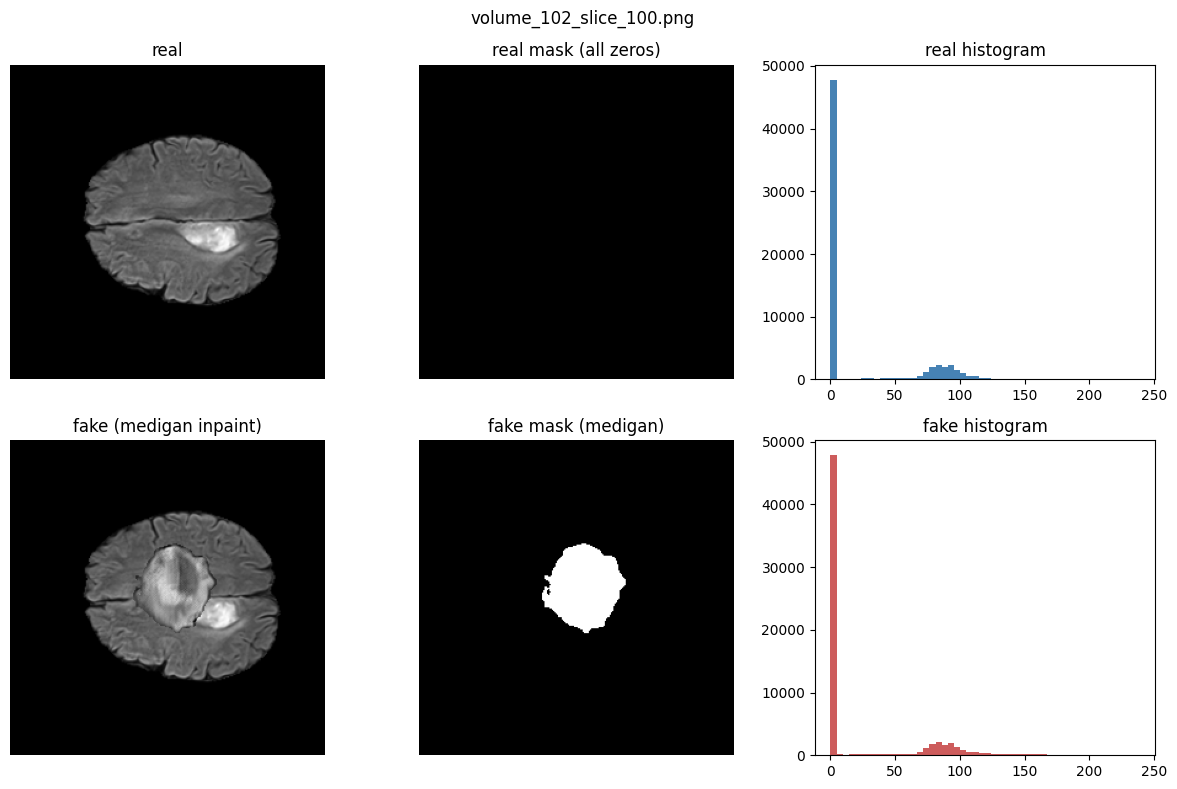

In [18]:
train_reals = sorted((out_dir / "train" / "real").glob("*.png"))
name = train_reals[0].name
real = np.array(Image.open(out_dir / "train" / "real" / name))
fake = np.array(Image.open(out_dir / "train" / "fake" / name))
fmask = np.array(Image.open(out_dir / "train" / "fake_masks" / name))

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
axes[0, 0].imshow(real, cmap="gray")
axes[0, 0].set_title("real")
axes[0, 0].axis("off")
axes[0, 1].imshow(np.zeros_like(real), cmap="gray", vmin=0, vmax=255)
axes[0, 1].set_title("real mask (all zeros)")
axes[0, 1].axis("off")
axes[0, 2].hist(real.ravel(), bins=50, color="steelblue")
axes[0, 2].set_title("real histogram")
axes[1, 0].imshow(fake, cmap="gray")
axes[1, 0].set_title("fake (medigan inpaint)")
axes[1, 0].axis("off")
axes[1, 1].imshow(fmask, cmap="gray")
axes[1, 1].set_title("fake mask (medigan)")
axes[1, 1].axis("off")
axes[1, 2].hist(fake.ravel(), bins=50, color="indianred")
axes[1, 2].set_title("fake histogram")
plt.suptitle(name)
plt.tight_layout()
plt.show()



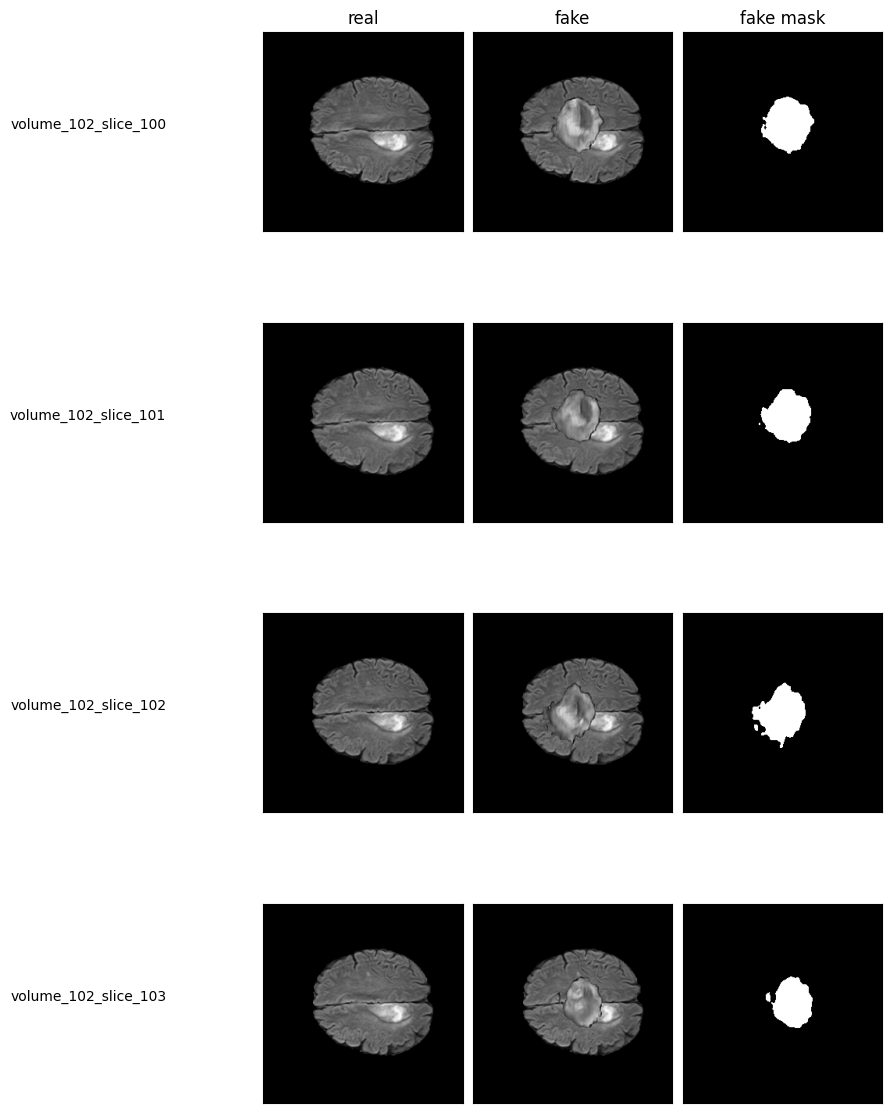

In [19]:
n_show = min(4, len(train_reals))
fig, axes = plt.subplots(n_show, 3, figsize=(9, 3 * n_show))
if n_show == 1:
    axes = np.expand_dims(axes, 0)

for row, p in enumerate(train_reals[:n_show]):
    r = np.array(Image.open(p))
    f = np.array(Image.open(out_dir / "train" / "fake" / p.name))
    m = np.array(Image.open(out_dir / "train" / "fake_masks" / p.name))
    axes[row, 0].imshow(r, cmap="gray")
    axes[row, 0].set_ylabel(p.stem, rotation=0, labelpad=70, ha="right")
    axes[row, 0].set_xticks([])
    axes[row, 0].set_yticks([])
    axes[row, 1].imshow(f, cmap="gray")
    axes[row, 1].set_xticks([])
    axes[row, 1].set_yticks([])
    axes[row, 2].imshow(m, cmap="gray")
    axes[row, 2].set_xticks([])
    axes[row, 2].set_yticks([])

axes[0, 0].set_title("real")
axes[0, 1].set_title("fake")
axes[0, 2].set_title("fake mask")
plt.tight_layout()
plt.show()



## 8. Leakage audit

We check the files on disk, not just the in-memory split:

- patient IDs across train / val / test
- exact duplicate images (MD5)
- real/fake pairing (same filename in both folders)
- real masks are empty, fake masks come from medigan and cover edited pixels


In [20]:
import hashlib
from collections import defaultdict


def md5_of(path):
    h = hashlib.md5()
    with open(path, "rb") as f:
        h.update(f.read())
    return h.hexdigest()


print("=== patient IDs ===")
ids = {}
for split in ["train", "val", "test"]:
    s = set()
    for kind in ["real", "fake"]:
        for p in (out_dir / split / kind).glob("*.png"):
            s.add(pid_from_name(p.name))
    ids[split] = s
    print(f"  {split}: {len(s)} patients")

print("train & val:", len(ids["train"] & ids["val"]))
print("train & test:", len(ids["train"] & ids["test"]))
print("val & test:", len(ids["val"] & ids["test"]))
assert len(ids["train"] & ids["val"]) == 0
assert len(ids["train"] & ids["test"]) == 0
assert len(ids["val"] & ids["test"]) == 0

print("\n=== exact duplicates (MD5) ===")
seen = defaultdict(list)
for split in ["train", "val", "test"]:
    for kind in ["real", "fake"]:
        for p in (out_dir / split / kind).glob("*.png"):
            seen[md5_of(p)].append(f"{split}/{kind}/{p.name}")
dups = [v for v in seen.values() if len(v) > 1]
print("duplicate groups:", len(dups))
assert len(dups) == 0, dups[:3]

print("\n=== mask check (sample of fakes) ===")
for split in ["train", "val", "test"]:
    fills, mads, real_max = [], [], []
    fake_paths = list((out_dir / split / "fake").glob("*.png"))
    if len(fake_paths) > 80:
        rng = np.random.default_rng(0)
        fake_paths = list(rng.choice(fake_paths, size=80, replace=False))
    for p in fake_paths:
        real = np.array(Image.open(out_dir / split / "real" / p.name))
        fake = np.array(Image.open(p))
        m = np.array(Image.open(out_dir / split / "fake_masks" / p.name)) > 127
        rm = np.array(Image.open(out_dir / split / "real_masks" / p.name))
        fills.append(float(m.mean()))
        mads.append(float(np.abs(fake.astype(np.float32) - real.astype(np.float32))[m].mean()) if m.any() else 0.0)
        real_max.append(int(rm.max()))
    print(
        f"  {split}: n={len(fills)}  mask fill={np.mean(fills):.4f}  "
        f"MAD inside mask={np.mean(mads):.2f}  real_mask_max={max(real_max) if real_max else None}"
    )

print("\nleakage audit passed: host patients are disjoint, no duplicate files.")



=== patient IDs ===
  train: 258 patients
  val: 55 patients
  test: 56 patients
train & val: 0
train & test: 0
val & test: 0

=== exact duplicates (MD5) ===
duplicate groups: 0

=== mask check (sample of fakes) ===
  train: n=80  mask fill=0.0428  MAD inside mask=47.12  real_mask_max=0
  val: n=80  mask fill=0.0431  MAD inside mask=45.21  real_mask_max=0
  test: n=80  mask fill=0.0423  MAD inside mask=50.53  real_mask_max=0

leakage audit passed: host patients are disjoint, no duplicate files.


## Done

The full dataset is under `ai/dataset/`. Each real FLAIR slice has a matching
medigan fake and the model's own anomaly mask.

To try a smaller run, set `USE_ALL_PATIENTS = False` and rerun from section 3.
Do **not** mix these images with the old stamped `cv2.seamlessClone` fakes.
